# 第9章 储能运维知识助手

已执行的离线教学Notebook。16份自编规程，24道开发题、36道测试题。目标属性由任务字段明确提供；回答采用确定性模板。依次观察范围、检索、出处、计算与故障。

## 1 读取语料并定位当前与历史证据

In [1]:
from pathlib import Path
import sys, json, copy, io
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "chapters/ch09/core.py").exists())
sys.path.insert(0, str(root / "chapters/ch09"))
from core import Index, ROOT
from tools_readonly import execute, example_request
questions = json.loads((ROOT / "data/questions.json").read_text(encoding="utf-8"))
index = Index(12)
query = next(q for q in questions if q["id"] == "DEV01")
for date in ["2026-08-01", "2026-11-14", "2025-01-01"]:
    print(date, index.answer({**query, "as_of": date}))
print("文档/证据块:", len({c["meta"]["doc_id"] for c in index.chunks}), len(index.chunks))

2026-08-01 {'status': 'grounded', 'claims': [{'metric': 'energy', 'value': '800', 'unit': 'kWh', 'chunk_id': 'D01-C01', 'quote': '## D01-C01 额定储能量用于容量账本\nBAT-A：额定储能量用于容量账本。\n事实|energy|800|kWh', 'sha256': '87e4025fe89d4dcb3e979c973e68b598733fa743a917946a43796fe34ed57d60'}], 'evidence': ['D01-C01'], 'text': '教学语料记录：800 kWh。出处：D01-C01，第4—6行。'}
2026-11-14 {'status': 'grounded', 'claims': [{'metric': 'energy', 'value': '1000', 'unit': 'kWh', 'chunk_id': 'D02-C01', 'quote': '## D02-C01 额定储能量用于容量账本\nBAT-A：额定储能量用于容量账本。\n事实|energy|1000|kWh', 'sha256': '9766b459828027b176eb8bffacbfbd637e0788199750edb8caf76a521b40014a'}], 'evidence': ['D02-C01'], 'text': '教学语料记录：1000 kWh。出处：D02-C01，第4—6行。'}
2025-01-01 {'status': 'needs_evidence', 'claims': [], 'evidence': [], 'text': '当前对象、日期与授权范围内，前k项未检得目标属性证据。请补充资料或调整检索。'}
文档/证据块: 16 37


## 2 比较三种方法的实时排序

修改text保留metric，观察口语改写如何改变候选排序。

In [2]:
q = next(q for q in questions if q["id"] == "TEST01")
for method in ["bm25", "tfidf", "lsa"]:
    hits = index.search(q, method)
    print(method, [(h["chunk"]["id"], round(h["score"], 4)) for h in hits])
    print("状态:", index.answer(q, method)["status"])
conflict = {**query, "text": "BAT-A复核温度", "metric": "review_temperature"}
print("冲突:", index.answer(conflict))

bm25 [('D14-C02', 11.3209), ('D02-C03', 7.6699), ('D14-C03', 6.3018)]
状态: needs_evidence
tfidf [('D02-C03', 0.3666), ('D14-C02', 0.3267), ('D14-C03', 0.1859)]
状态: needs_evidence
lsa [('D02-C03', 0.9528), ('D14-C02', 0.8652), ('D14-C03', 0.507)]
状态: needs_evidence
冲突: {'status': 'conflict', 'claims': [], 'evidence': ['D04-C01', 'D05-C01'], 'text': '有效范围内存在同属性数值冲突，请由资料负责人确定采用版本。'}


## 3 检验真实引用中的错误量值

In [3]:
hits = index.search(query)
payload = {"claims": index.answer(query)["claims"]}
print("正确主张:", index.validate_generated(query, payload, hits))
bad = copy.deepcopy(payload)
bad["claims"][0]["value"] = "9999"
print("错误量值:", index.validate_generated(query, bad, hits))
assert index.validate_generated(query, payload, hits)
assert not index.validate_generated(query, bad, hits)

正确主张: True
错误量值: False


## 4 只读计算与单位归一化

In [4]:
request = example_request()
normal = execute(request)
print("电池可供能时间:", normal["result"])
converted = copy.deepcopy(request)
converted["arguments"]["energy"] = {"value": 1000000, "unit": "Wh"}
converted["arguments"]["power"] = {"value": 300000, "unit": "W"}
print("Wh/W归一化:", execute(converted)["result"])
print("水体显热:", execute(example_request("water_sensible_heat"))["result"])
assert abs(normal["result"]["value"] - 1.9) < 1e-12

电池可供能时间: {'value': 1.9000000000000004, 'unit': 'h'}
Wh/W归一化: {'value': 1.9000000000000004, 'unit': 'h'}
水体显热: {'value': 139.33333333333334, 'unit': 'kWh'}


## 5 绘制当前计算关系

曲线由本单元参数直接计算，点标出当前SOC。

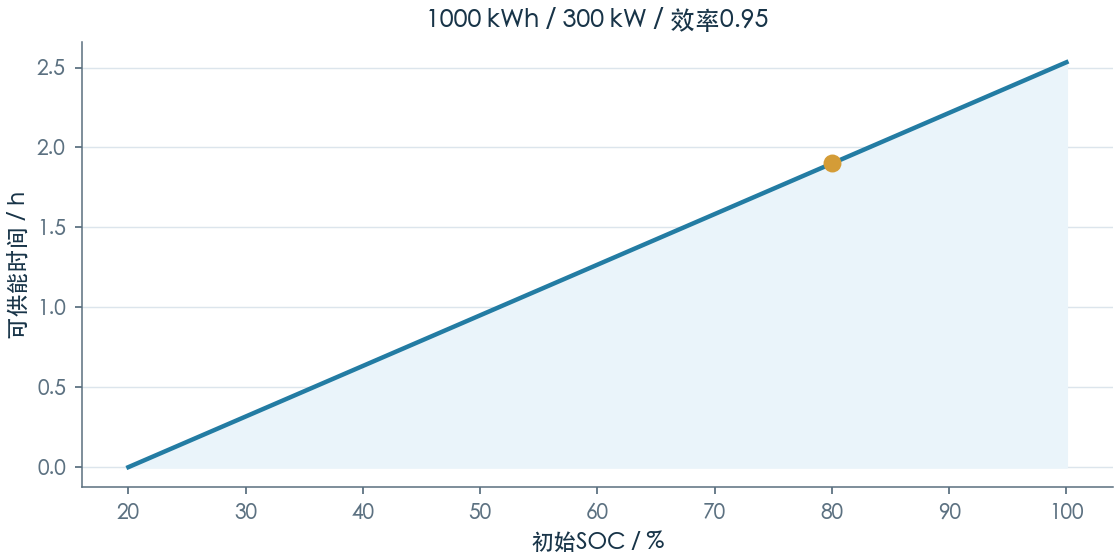

In [5]:
import numpy as np
from visual_style import setup, style, plt
from IPython.display import Image, display
setup()
soc = np.linspace(.2, 1, 100)
hours = 1000 * (soc - .2) * .95 / 300
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(soc * 100, hours, color="#237CA3", linewidth=2)
ax.fill_between(soc * 100, hours, color="#EAF4FA")
ax.scatter([80], [1.9], color="#D49C37", s=50, zorder=3)
ax.set(xlabel="初始SOC / %", ylabel="可供能时间 / h", title="1000 kWh / 300 kW / 效率0.95")
style(ax)
buffer = io.BytesIO(); fig.savefig(buffer, format="png", dpi=160); plt.close(fig)
display(Image(data=buffer.getvalue()))

## 6 保留超时与错误响应记录

In [6]:
for fault in ["timeout_once", "timeout_twice", "wrong_unit", "wrong_value"]:
    result = execute(request, fault)
    print(fault, result["status"], [(x["attempt"], x["event"]) for x in result["attempts"]])
print("练习：改变问题、检索数量或工具参数，记录新增缺口和对应证据。")

timeout_once ok [(1, 'timeout'), (2, 'validated')]
timeout_twice timeout [(1, 'timeout'), (2, 'timeout')]
wrong_unit invalid_result [(1, 'invalid_result')]
wrong_value invalid_result [(1, 'invalid_result')]
练习：改变问题、检索数量或工具参数，记录新增缺口和对应证据。
